# График моей функции 

(6, matplotlib) Напишите функцию, которая отрисовывает функцию на определенном интервале.

Аргументы функции:
- функция для отрисовки `f`,
- начало интервала отрисовки `min_x`,
- конец интервала отрисовки `max_x`,
- количество точек по оси абсцисс `N`,
- ограничение снизу по оси ординат `min_y`,
- ограничение сверху по оси ординат `max_y`
- цвет кривой красный, кривая непрерывная (1).
- логарифмический масштаб по оси ординат (1)
- сетка (1)

Результат сохранить в файл function.jpeg (1). Дополнительно отрисуйте производную функции на том же графике (2). Параметры отрисовки производной по умолчанию.

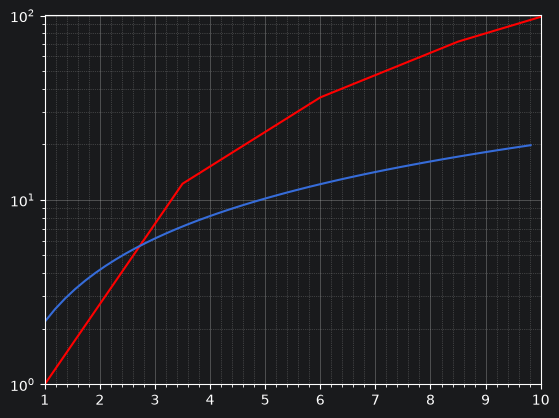

In [81]:
import numpy as np
from matplotlib import pyplot as plt
def my_plot(f, min_x, max_x, N, min_y, max_y):
    x = np.linspace(min_x, max_x + 1, N)
    y = list(map(f, x))
    plt.semilogy(x, y, color='red')
    xp = np.linspace(min_x, max_x, 10*N)
    yp = [(f(xp[i+1])-f(xp[i]))/(xp[i+1]-xp[i]) for i in range(10*N-1)]
    plt.semilogy(xp[:-1], yp)
    plt.xlim(min_x, max_x)
    plt.ylim(min_y, max_y)
    plt.minorticks_on()
    plt.grid()
    plt.grid(which="minor", linestyle=":")
    plt.savefig("function.jpeg")
    plt.show()
my_plot(lambda x: x**2, 1, 10, 5, 1, 101)

# Гистограмма моих данных

(6, numpy/matplotlib) Функция на вход принимает три параметра:

- массив случайных пар `(x, y)` чисел `data`,
- точки разбиения оси абсцисс `x`,
- точки разбиения оси ординат `y`,
- пороговое значение `threshold`

Требования
- Постройте одномерную гистограмму распределения данных (требуется изменить размер входного массива `data` до одномерного) (1.5)
- Сохраните в `histograms_0.png` (0.5).
- Постройте двумерную гистограмму распределения данных при условии: если в корзине (бине/ячейке гистограммы) значение меньше `treshold`, то требуется выставить 0, иначе -- 1 (1.5).
- Сохраните в `histograms_1.png` (0.5).
- Постройте двумерную гистограмму распределения данных при условии: если в корзине (бине/ячейке гистограммы) значение больше `treshold`, то требуется выставить 0, иначе -- значение, которое было в гистограмме (1.5).
- Сохраните в `histograms_2.png` (0.5).
- Не забудьте выставить colorbar (1).

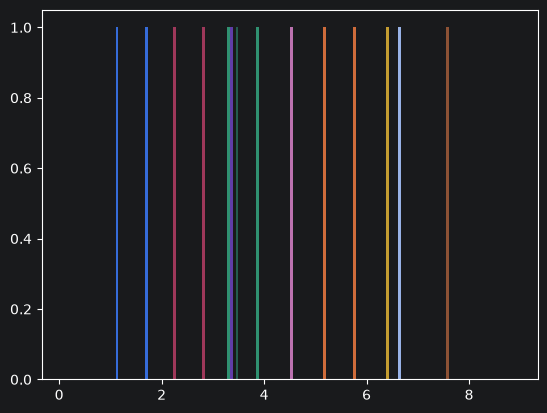

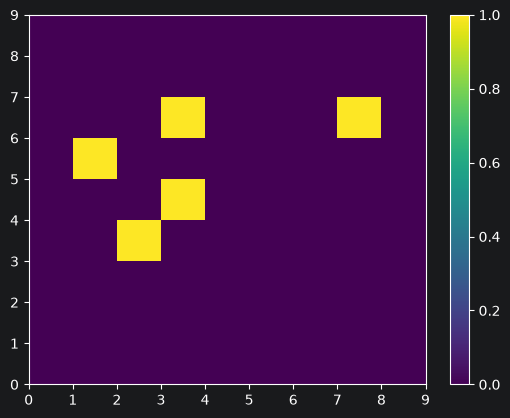

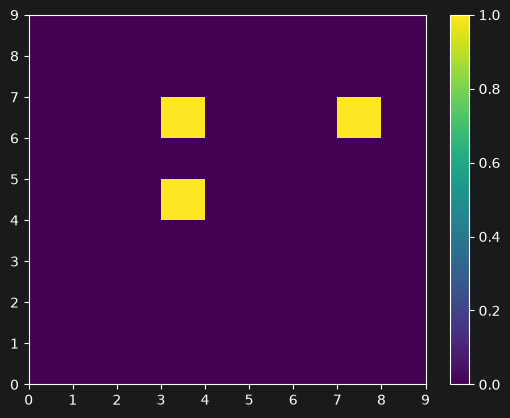

<Figure size 640x480 with 0 Axes>

In [77]:
def my_hist(data, x, y, treshold):
    data = np.array(data)
    d1 = data.reshape(1, -1)
    plt.hist(d1, bins=x)
    plt.show()
    plt.savefig("histograms_0.png")
    d2 = data.T
    h, xd, yd, q = plt.hist2d(d2[0], d2[1], bins=[x, y])
    h = np.where(h<treshold, 0, 1)
    q = plt.pcolormesh(xd, yd, h.T)
    c = plt.colorbar()
    plt.show()
    plt.savefig("histograms_1.png")
    h, xd, yd, q = plt.hist2d(d2[0], d2[1], bins=[x, y])
    h[h>treshold]=0
    q = plt.pcolormesh(xd, yd, h.T)
    c = plt.colorbar()
    plt.show()
    plt.savefig("histograms_2.png")
my_hist([(1,5),(2,3), (3,6), (3,4), (7,6), (1,5),(2,3)], range(10), range(10), 1)

# ~Кино~Игрокритик

Время стать критиком игр (`video-games.csv`). Требуется создать словарь (ключ словаря указан вначале пункта) с соответствующим значением из пункта (тип значения указан в конце строки).

- (1) `"n_games"` Найдите полное количество игр в таблице `int`
- (2) `"by_years"` Определите количество игр за каждый год `pd.DataFrame`
- (2) `"mean_price"` Посчитайте среднюю цену игр, где создатель (`"publisher"`) EA `pd.DataFrame`
- (2) `"age_max_price"` Найдите самые дорогие игры среди игр с разным возрастным рейтингом (`"age_rating"`) `pd.DataFrame`
- (2) `"mean_raiting_1_2"` Найдите средний рейтинг игр, где количество игроков (`"max_players"`) 1 или 2 `float`
- (2) `"min_max_price"` Найдите максимальную и минимальную цену (`"price"`) игр с разным возрастным рейтингом (`"age_rating"`) и среднее значение метрики продаж (`"sales_metric"`). Отсортируйте по убыванию максимальной
цены `pd.DataFrame`
- (2) `"n_games_by_age"` Найдите количество игр в группах с разным рейтингом (`"review_raiting"`) `pd.DataFrame`
- (2) `"same_price_raiting"` Найти игры, у которых совпадает цена (`"price"`) с точностью до округления вниз и совпадает рейтинг (`"review_raiting"`) с точностью до десятков `pd.DataFrame`
- (3) `"creators"` Определите всех возможных создателей игр (`"publisher"`). В ответе не может быть коллабораций создателей `list`
- (4) "max_raiting_by_years" Для каждого года (`"year"`) определите игры (вывести название (`"title"`) в отдельном столбце) с максимальным пользовательским рейтингом (`"review_raiting"`) `pd.DataFrame`
- (1) "empty_creators" Найдите количество игр, у которых отсутствует создатель (`"publisher"`) `int` Ответом является словарь.

In [51]:
import pandas as pd
d = {}
df = pd.read_csv('video-games.csv')
d['n_games'] = int(len(df))
print(d['n_games'])
d['by_years'] = df.groupby("year", as_index=False).size()
print(d['by_years'])
d['mean_price'] = float(df[df["publisher"]=='EA']["price"].mean())
print(d['mean_price'])
d['age_max_price'] = df.groupby("age_raiting").agg({"price":'max'})
print(d['age_max_price'])
d['mean_raiting_1_2'] = float(df[(df['max_players'] == 1) | (df['max_players'] == 2)]['review_raiting'].mean())
print(d['mean_raiting_1_2'])
d['min_max_price'] = df.groupby("age_raiting", as_index=False).agg(
              min_price=("price", "min"),
              max_price=("price", "max"),
              mean_sales_metric=("sales_metric", "mean")).sort_values("max_price", ascending=False) # убывание не reverse, a ascending
print(d['min_max_price'])
d['n_games_by_age'] = df.groupby("review_raiting").size()
print(d['n_games_by_age'])
df['_price'] = df['price'].astype(int)
df['_review_raiting'] = df['review_raiting'].round(-1)
d['same_price_raiting'] = df[df.groupby(['_price', '_review_raiting']).transform("size") > 1]['title']
print(d['same_price_raiting'])
d['creators']=df[~((df['publisher'].str.contains(',')) | (df['publisher'].isna()))]['publisher'].unique()
print(d['creators'])
t = df[df["review_raiting"]==df.groupby("year")["review_raiting"].transform("max")]
d['max_raiting_by_years'] = pd.DataFrame({'year':t['year'], 'title':t['title']})
print(d['max_raiting_by_years'])
d['empty_creators'] = int(len(df[df["publisher"].isna()]))
print(d['empty_creators'])

1212
   year  size
0  2004    22
1  2005   134
2  2006   263
3  2007   414
4  2008   379
15.477272727272727
             price
age_raiting       
E            44.95
M            39.95
T            49.95
68.56292682926829
  age_raiting  min_price  max_price  mean_sales_metric
2           T       4.95      49.95           0.538702
0           E       4.95      44.95           0.543788
1           M       4.95      39.95           0.357131
review_raiting
19    1
20    1
25    1
27    2
28    2
     ..
94    7
95    2
96    2
97    1
98    2
Length: 71, dtype: int64
0                   Super Mario 64 DS
1              Lumines: Puzzle Fusion
2                  WarioWare Touched!
3            Hot Shots Golf: Open Tee
4                        Spider-Man 2
                    ...              
1206    Rhapsody: A Musical Adventure
1207           Secret Files: Tunguska
1208                   Fading Shadows
1210           Secret Files: Tunguska
1211                   Chicken Hunter
Name: title, 